# LLM-Based Approach (Task 5): zero-shot, few-shot, structured

Evaluates sentiment classification with **no training**, on the same `domain_test` split used by the BERT strategies (A / B / C / Sequential), then compares everything in one table (accuracy, precision, recall, F1, confusion matrix).

Two LLM backends:
- **Claude API** (`claude-haiku-5-5`): needs `ANTHROPIC_API_KEY` in your environment (never paste the key into the notebook). Structured mode uses forced tool-use with an enum, so the label is always valid.
- **Local** (`Qwen/Qwen2.5-0.5B-Instruct`, the lightest practical instruct model): the label is chosen by scoring each candidate label's log-probability, so the output is always valid too.

Workflow: keep `N_SAMPLE = 20` for a dry run, check the numbers, then set `N_SAMPLE = None` for the full test set. Delete `results/llm_raw_*` after changing any prompt (raw outputs are cached so an interrupted run resumes).

In [ ]:
# Run from anywhere: move to the repo root so data/, results/ and checkpoints/ paths resolve.
import os
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "README.md").exists() and (p / "data").is_dir())
os.chdir(ROOT)
print("working directory:", Path.cwd())

In [2]:
import torch
import os, json, re, time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, ConfusionMatrixDisplay

# ---- settings -------------------------------------------------------------
TASK = "binary"            # "binary" (positive/negative, primary) | "12class"
N_SAMPLE = None              # dry run; None = full domain_test
K_SHOT = 2                 # few-shot examples per label (from domain_train only)
RUN_CLAUDE = True       # needs ANTHROPIC_API_KEY and `pip install anthropic`
RUN_LOCAL = False
MODES = ["zeroshot", "fewshot", "structured"]
CLAUDE_MODEL = "claude-haiku-5-5"
LOCAL_MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
SEED = 42
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)

## 1. Data: same splits as `bert_final.ipynb`

In [3]:
domain = pd.read_csv("data/domain_clean.csv")
if TASK == "binary":
    df = domain[["text", "senti_label"]].rename(columns={"senti_label": "label"})
    df["label"] = df["label"].map({"bullish": "positive", "bearish": "negative"})
else:
    df = domain[["text", "emo_label"]].rename(columns={"emo_label": "label"})

# identical split recipe to the BERT notebook -> identical domain_test rows and order
train, rest = train_test_split(df, test_size=.3, stratify=df["label"], random_state=SEED)
val, test = train_test_split(rest, test_size=.5, stratify=rest["label"], random_state=SEED)
test = test.reset_index(drop=True)

LABELS = sorted(df["label"].unique())
if N_SAMPLE and N_SAMPLE < len(test):
    sub = train_test_split(test, train_size=N_SAMPLE, stratify=test["label"], random_state=SEED)[0].sort_index()
else:
    sub = test
shots = train.groupby("label").sample(K_SHOT, random_state=SEED).sample(frac=1, random_state=SEED)  # few-shot pool: train only
print(f"task={TASK} | labels={LABELS} | evaluating {len(sub)}/{len(test)} test rows | {len(shots)} few-shot examples")

task=binary | labels=['negative', 'positive'] | evaluating 1500/1500 test rows | 4 few-shot examples


## 2. Prompts

In [4]:
if TASK == "binary":
    DEFS = {"positive": "bullish: the author expects the stock/market to rise, praises it, or reports good news",
            "negative": "bearish: the author expects the stock/market to fall, criticises it, or reports bad news"}
    RULE = "Judge the post's stance toward the stock or market, not the writer's mood."
else:
    DEFS = {"ambiguous": "no clear single emotion, or mixed/unclear",
            "amusement": "jokes, memes, finds something funny",
            "anger": "angry, outraged, hostile, annoyed",
            "anxiety": "worried, nervous or uneasy about risk or losses",
            "belief": "conviction or trust in a thesis; confidence, gratitude, pride",
            "confusion": "unsure, asking questions, curious",
            "depression": "sad, regretful, disappointed, hopeless about losses",
            "disgust": "contempt or revulsion",
            "excitement": "thrilled, hyped, joyful",
            "optimism": "hopeful, expects good outcomes",
            "panic": "fear, alarm, urgency to sell",
            "surprise": "shocked by an unexpected move"}
    RULE = "Judge the emotion the author expresses about the market or stock."

def system_prompt(mode):
    s = ("You classify short stock-market social-media posts. "
         f"Answer with exactly one label from: {', '.join(LABELS)}. Reply with the label only.")
    if mode == "structured":
        s += "\n\nLabel definitions:\n" + "\n".join(f"- {l}: {DEFS[l]}" for l in LABELS)
        s += f"\n\nRules:\n- {RULE}\n- If unclear, choose the closest label; never invent a label."
    return s

def build_messages(mode, text):
    msgs = []
    if mode == "fewshot":
        for _, r in shots.iterrows():
            msgs += [{"role": "user", "content": r["text"]}, {"role": "assistant", "content": r["label"]}]
    return msgs + [{"role": "user", "content": text}]

def parse_label(raw):
    hits = [(m.start(), l) for l in LABELS for m in re.finditer(rf"\b{l}\b", raw.lower())]
    return min(hits)[1] if hits else "invalid"

print(system_prompt("structured"))

You classify short stock-market social-media posts. Answer with exactly one label from: negative, positive. Reply with the label only.

Label definitions:
- negative: bearish: the author expects the stock/market to fall, criticises it, or reports bad news
- positive: bullish: the author expects the stock/market to rise, praises it, or reports good news

Rules:
- Judge the post's stance toward the stock or market, not the writer's mood.
- If unclear, choose the closest label; never invent a label.


## 3. Backends

In [5]:
client = None
if RUN_CLAUDE:
    import anthropic
    from dotenv import load_dotenv
    load_dotenv()   # reads ANTHROPIC_API_KEY from a local .env file (gitignored) if the kernel has no such variable
    assert os.environ.get("ANTHROPIC_API_KEY"), "Set ANTHROPIC_API_KEY in your environment first"
    # Accept-Encoding without "br": the installed brotlicffi (1.1.0) is too old for httpx2 and breaks decoding of brotli responses
    client = anthropic.Anthropic(default_headers={"Accept-Encoding": "gzip, deflate"})

TOOL = {"name": "classify", "description": "Record the label for the post.",
        "input_schema": {"type": "object",
                         "properties": {"reason": {"type": "string", "description": "one short sentence"},
                                        "label": {"type": "string", "enum": LABELS}},
                         "required": ["reason", "label"]}}

def claude_predict(mode, text):
    kw = dict(model=CLAUDE_MODEL, max_tokens=200, system=system_prompt(mode), messages=build_messages(mode, text))
    if mode == "structured":
        r = client.messages.create(**kw, tools=[TOOL], tool_choice={"type": "tool", "name": "classify"})
        inp = next(b.input for b in r.content if b.type == "tool_use")
        return inp["label"], inp["reason"]
    kw["max_tokens"] = 10
    try:
        r = client.messages.create(**kw, thinking={"type": "disabled"})   # a leading ThinkingBlock would eat max_tokens and has no .text
    except anthropic.BadRequestError:                                      # model rejects the switch: leave room for thinking instead
        kw["max_tokens"] = 400
        r = client.messages.create(**kw)
    raw = "".join(b.text for b in r.content if b.type == "text").strip()
    return parse_label(raw), raw

tok = lm = dev = None
def load_local():
    global tok, lm, dev
    from transformers import AutoModelForCausalLM, AutoTokenizer
    dev = "mps" if torch.backends.mps.is_available() else "cpu"
    tok = AutoTokenizer.from_pretrained(LOCAL_MODEL)
    lm = AutoModelForCausalLM.from_pretrained(LOCAL_MODEL, torch_dtype=torch.float16 if dev == "mps" else torch.float32).to(dev).eval()

@torch.no_grad()
def local_predict(mode, text):
    """Constrained choice: score every candidate label (sum of token log-probs) and take the best."""
    msgs = [{"role": "system", "content": system_prompt(mode)}] + build_messages(mode, text)
    prompt = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    p_ids = tok(prompt, return_tensors="pt").input_ids.to(dev)
    scores = {}
    for l in LABELS:
        l_ids = tok(l, add_special_tokens=False, return_tensors="pt").input_ids.to(dev)
        logits = lm(torch.cat([p_ids, l_ids], 1)).logits[0, p_ids.shape[1] - 1:-1].float()
        scores[l] = torch.log_softmax(logits, -1).gather(1, l_ids[0].unsqueeze(1)).sum().item()
    return max(scores, key=scores.get), json.dumps({k: round(v, 2) for k, v in scores.items()})

## 4. Run (cached and resumable)

In [6]:
def run(backend, mode, force=False):
    path = RESULTS / f"llm_raw_{backend}_{mode}_{TASK}.csv"
    done = pd.read_csv(path, index_col="idx") if path.exists() and not force else pd.DataFrame(columns=["pred", "raw"])
    todo = [i for i in sub.index if i not in done.index]
    fn = claude_predict if backend == "claude" else local_predict
    t0 = time.time()
    def one(i):
        try:
            return i, *fn(mode, sub.loc[i, "text"])
        except Exception as e:                      # keep the run going; counted as invalid
            return i, "invalid", f"ERROR {type(e).__name__}: {e}"
    new = []
    if backend == "claude" and todo:
        first, todo = todo[0], todo[1:]
        new.append((first, *fn(mode, sub.loc[first, "text"])))   # no try/except: auth or model-name errors stop the run here, before thousands of calls
        with ThreadPoolExecutor(8) as ex:
            new += list(ex.map(one, todo))
    else:
        new = [one(i) for i in todo]
    if new:
        add = pd.DataFrame(new, columns=["idx", "pred", "raw"]).set_index("idx")
        done = pd.concat([done, add])
        done.index.name = "idx"
        done[~done["raw"].astype(str).str.startswith("ERROR")].to_csv(path)   # failed calls are not cached, so a rerun retries them
    errs = pd.Series([r for _, _, r in new if str(r).startswith("ERROR")]).str[:160].value_counts()
    if len(errs):
        print(f"  {errs.sum()} calls FAILED (not cached, rerun retries them):\n{errs.to_string()}")
    print(f"{backend}/{mode}: {len(new)} new calls in {time.time() - t0:.0f}s ({(done['pred'] == 'invalid').sum()} invalid)")
    out = done.loc[sub.index].copy()
    out.insert(0, "true", sub["label"])
    out.insert(0, "text", sub["text"])
    out[["true", "pred"]].to_csv(RESULTS / f"pred_LLM_{backend}_{mode}_{TASK}.csv", index=False)  # same format as BERT preds
    return out

runs = {}
if RUN_LOCAL:
    load_local()
    for m in MODES:
        runs[f"Local-{m}"] = run("local", m)
if RUN_CLAUDE:
    for m in MODES:
        runs[f"Claude-{m}"] = run("claude", m)

claude/zeroshot: 262 new calls in 32s (3 invalid)
claude/fewshot: 79 new calls in 14s (8 invalid)
claude/structured: 0 new calls in 0s (0 invalid)


## 5. Comparison with the BERT strategies (same rows)

In [7]:
def metrics(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, labels=LABELS, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y, p), "precision": pr, "recall": rc, "macro_f1": f1}

BERT_FILES = ({"A: General only": "A_bin", "B: Domain only": "B1_bin", "C: Mixed": "C_bin", "Sequential": "Seq_bin"}
              if TASK == "binary" else
              {"A: General only": "S2a", "B: Domain only": "S1", "C: Mixed": "S3", "Sequential": "S2"})
preds = {}
for name, f in BERT_FILES.items():
    p = pd.read_csv(RESULTS / f"pred_{f}.csv")
    if len(p) == len(test) and (p["true"].values == test["label"].values).all():
        preds["BERT " + name] = p.loc[sub.index, "pred"].values
    else:
        print(f"skip {name}: pred_{f}.csv does not align with this test split")
for name, out in runs.items():
    preds[name] = out["pred"].values
for backend in ["Local", "Claude"]:                     # also show earlier cached runs that were not re-run now
    for m in MODES:
        name, f = f"{backend}-{m}", RESULTS / f"pred_LLM_{backend.lower()}_{m}_{TASK}.csv"
        if name not in preds and f.exists():
            c = pd.read_csv(f)
            if len(c) == len(sub) and (c["true"].values == sub["label"].values).all():
                preds[name] = c["pred"].values

y = sub["label"].values
table = pd.DataFrame({n: metrics(y, p) for n, p in preds.items()}).T
table["invalid"] = [int((np.asarray(p) == "invalid").sum()) for p in preds.values()]
table = table.round(4).sort_values("macro_f1", ascending=False)
table.to_csv(RESULTS / f"llm_comparison_{TASK}.csv")
print(f"n = {len(sub)} test rows ({TASK})")
table

n = 1500 test rows (binary)


,accuracy,precision,recall,macro_f1,invalid
BERT B: Domain only,0.8060,0.8044,0.8037,0.8040,0
Claude-structured,0.8007,0.7988,0.7992,0.7990,0
BERT Sequential,0.8000,0.7981,0.7986,0.7983,0
BERT C: Mixed,0.7827,0.7820,0.7845,0.7820,0
Claude-zeroshot,0.7560,0.7569,0.7576,0.7560,3
Claude-fewshot,0.7507,0.7548,0.7530,0.7521,8
Local-zeroshot,0.5967,0.6040,0.6034,0.5966,0
Local-fewshot,0.5920,0.6318,0.6119,0.5824,0
BERT A: General only,0.5813,0.5743,0.5630,0.5542,0
Local-structured,0.5480,0.5713,0.5642,0.5417,0


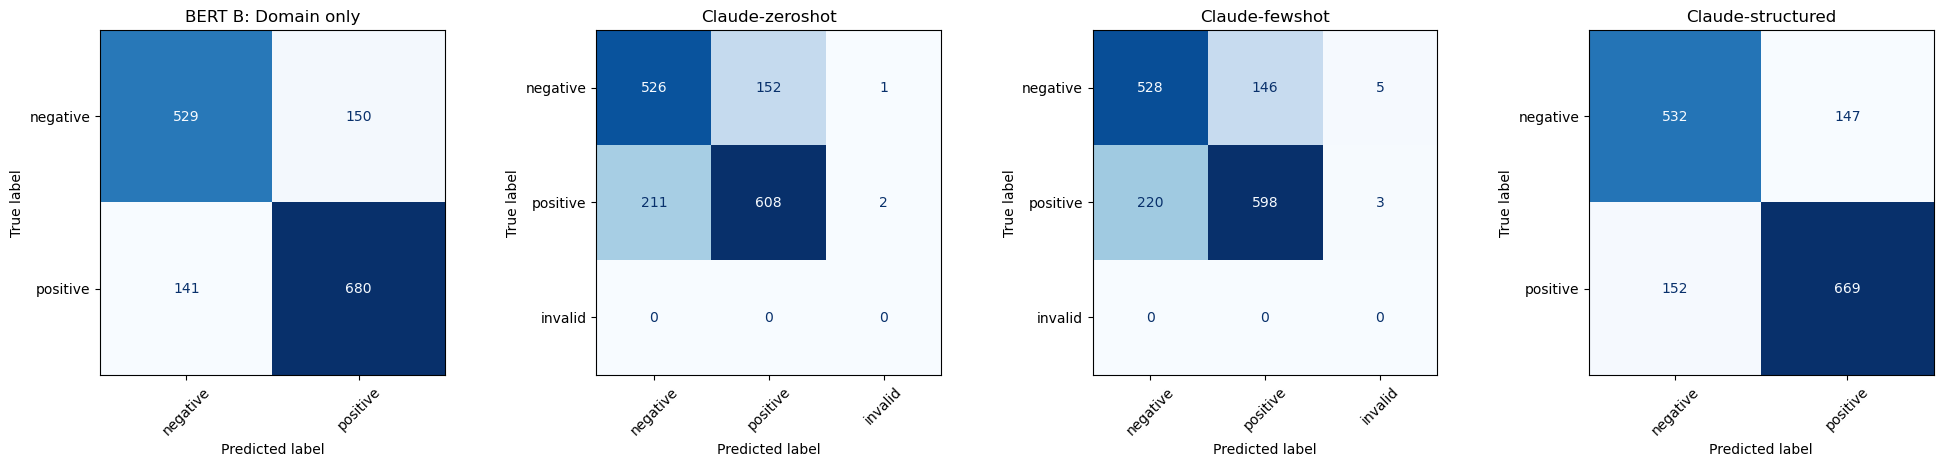

In [8]:
# confusion matrix of LLM & Bert model
bert_best = max((n for n in preds if n.startswith("BERT")), key=lambda n: metrics(y, preds[n])["macro_f1"], default=None)
show = ([bert_best] if bert_best else []) + list(runs)
fig, axes = plt.subplots(1, len(show), figsize=(5 * len(show), 4.6), squeeze=False)
for ax, n in zip(axes[0], show):
    labs = LABELS + (["invalid"] if "invalid" in set(preds[n]) else [])
    ConfusionMatrixDisplay.from_predictions(y, preds[n], labels=labs, xticks_rotation=45, cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(n)
plt.tight_layout(); plt.show()

## 6. Error analysis inputs (domain vocabulary, failures, bias)

In [9]:
# bias: share of each predicted label vs the true share
share = pd.DataFrame({"true": pd.Series(y).value_counts(normalize=True)})
for n, p in preds.items():
    share[n] = pd.Series(p).value_counts(normalize=True)
print(share.fillna(0).round(3).to_string())

# failures: posts the best LLM run got wrong (with its reason / scores) - read these for vocabulary errors
if runs:
    best_llm = max(runs, key=lambda n: metrics(y, preds[n])["macro_f1"])
    wrong = runs[best_llm][runs[best_llm]["true"] != runs[best_llm]["pred"]]
    print(f"\n{best_llm}: {len(wrong)} errors")
    pd.set_option("display.max_colwidth", 140)
    display(wrong[["text", "true", "pred", "raw"]].head(20))

           true  BERT A: General only  BERT B: Domain only  BERT C: Mixed  BERT Sequential  Claude-zeroshot  Claude-fewshot  Claude-structured  Local-zeroshot  Local-fewshot  Local-structured
positive  0.547                 0.699                0.553          0.507            0.543            0.507           0.496              0.544           0.439          0.301             0.335
negative  0.453                 0.301                0.447          0.493            0.457            0.491           0.499              0.456           0.561          0.699             0.665

Claude-structured: 299 errors


,text,true,pred,raw
6,Tesla FOR EVERY PUMP i doing like this CRAZY DANCE... [face with tears of joy],negative,positive,"The author celebrates Tesla's stock rises (""every pump""), expressing bullish sentiment."
8,Microsoft hmm was it a “joke”? [face with monocle],positive,negative,"The post questions whether Microsoft's recent move was a ""joke,"" implying criticism or disapproval of the stock."
10,Apple who even goes to an apple store? except teen age kids browsing [grinning squinting face],positive,negative,"The poster mocks Apple's retail stores and implies its customer base is just teens browsing, a dismissive, critical take on the company."
19,Tesla Imagine Elon says something magical? [pleading face],positive,negative,"The author sarcastically hopes Elon Musk will say something magical to move Tesla, implying the stock needs a boost and is currently lac..."
34,Tesla [crossed fingers dark skin tone] opposite of what it does most days of dip and then rip. Maybe rip then dip????,negative,positive,"The author jokes about Tesla's daily dip-and-rip pattern and hopes for a rip-then-dip, which reads as playful and not clearly bullish or..."
39,"Bummer that Tesla is not opening at $420 on Monday. It all makes sense, since everyone is smoking on the job and buying Tesla stocks [fa...",positive,negative,"The sarcastic post mocks Tesla's weak open and criticises buyers, implying the stock is falling or doing poorly."
40,Boeing that 135 line is so stubborn huh bears [frowning face],positive,negative,"The author calls Boeing's stock stubborn and says bears are frowning, implying the stock is struggling and likely to fall."
41,Tesla just wait for the news on flying cars in a couple years [smirking face] [face with tears of joy],positive,negative,"The sarcastic tone mocks Tesla's future flying-car promises, so the author is criticising the stock."
53,Alibaba trump is quiet [shushing face] on alibaba earnings this time ...he knows he xannot stop the storm now [cyclone] [flushed face],positive,negative,"The author suggests Trump is staying quiet on Alibaba earnings because he cannot stop the coming storm, implying bad news and a expected..."
60,Tesla Loading around 300 see you guys there [fire],negative,positive,"Author is buying Tesla near 300 and expressing enthusiasm, implying expected price rise."
